In [14]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect()
con.sql("CREATE OR REPLACE VIEW s AS SELECT * FROM read_csv('data/train.csv', nullstr = 'NULL')")

# A VIEW is a saved query, not a copy of the data. Every time you write FROM s, 
# DuckDB reads the Parquet file. It’s short to type and uses no extra memory.

CountBIGINT


In [15]:
summary = con.sql("SUMMARIZE s").df()
summary[["column_name", "column_type", "min", "max", "null_percentage"]]

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,column_name,column_type,min,max,null_percentage
0,srch_id,BIGINT,1,665574,0.00
1,date_time,TIMESTAMP,2012-11-01 00:01:37,2013-06-30 23:58:24,0.00
2,site_id,BIGINT,1,34,0.00
3,visitor_location_country_id,BIGINT,1,231,0.00
4,visitor_hist_starrating,DOUBLE,1.0,5.0,94.91
5,visitor_hist_adr_usd,DOUBLE,0.0,2768.93,94.88
6,prop_country_id,BIGINT,1,230,0.00
7,prop_id,BIGINT,1,140821,0.00
8,prop_starrating,BIGINT,0,5,0.00
9,prop_review_score,DOUBLE,0.0,5.0,0.15


In [16]:
con.sql("""
    SELECT
        AVG(click_bool)   AS click_rate,
        AVG(booking_bool) AS booking_rate,
        AVG(random_bool)  AS random_share
    FROM s
""").df()

,click_rate,booking_rate,random_share
0,0.044736,0.027889,0.29641


In [17]:
con.sql("""
    SELECT AVG(has_booking) AS searches_with_booking
    FROM (
        SELECT srch_id, MAX(booking_bool) AS has_booking
        FROM s
        GROUP BY srch_id
    )
""").df()

,searches_with_booking
0,0.692618


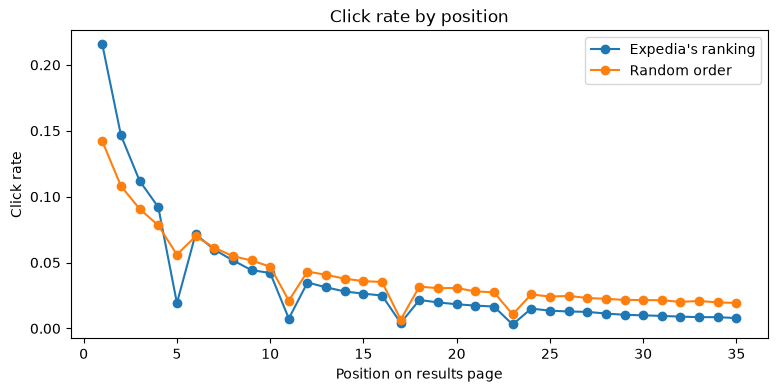

In [18]:
pos = con.sql("""
    SELECT position, random_bool,
           AVG(click_bool) AS click_rate
    FROM s
    WHERE position <= 35
    GROUP BY position, random_bool
    ORDER BY position
""").df()

fig, ax = plt.subplots(figsize=(9, 4))
for rb, grp in pos.groupby("random_bool"):
    label = "Random order" if rb == 1 else "Expedia's ranking"
    ax.plot(grp["position"], grp["click_rate"], marker="o", label=label)

ax.set_xlabel("Position on results page")
ax.set_ylabel("Click rate")
ax.set_title("Click rate by position")
ax.legend()
plt.show()

In [13]:
# reason to select position <= 35
con.sql("SELECT position, COUNT(*) AS n FROM s GROUP BY position ORDER BY position DESC").df()

,position,n
0,40,17
1,39,389
2,38,2637
3,37,9140
4,36,16721
5,35,21888
6,34,24793
7,33,26417
8,32,27909
9,31,29666


In [19]:
con.sql("""
    CREATE OR REPLACE TABLE base AS
    SELECT
        *,
        CASE
            WHEN booking_bool = 1 THEN 5
            WHEN click_bool   = 1 THEN 1
            ELSE 0
        END AS relevance
    FROM s
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

CountBIGINT
9917530


In [20]:
con.sql("""
    SELECT relevance,
           COUNT(*) AS n,
           COUNT(*) * 1.0 / SUM(COUNT(*)) OVER () AS share
    FROM base
    GROUP BY relevance
    ORDER BY relevance
""").df()

,relevance,n,share
0,0,9473858,0.955264
1,1,167079,0.016847
2,5,276593,0.027889


In [21]:
con.sql("""
    SELECT COUNT(*) AS bookings_without_click
    FROM base
    WHERE booking_bool = 1 AND click_bool = 0
""").df()

,bookings_without_click
0,0


In [22]:
TARGET_COLS = ["click_bool", "booking_bool", "gross_bookings_usd", "relevance"]
LEAKY_COLS  = ["position"]
EVAL_ONLY   = ["random_bool"]
ID_COLS     = ["srch_id", "prop_id", "date_time", "srch_destination_id"]

EXCLUDE = TARGET_COLS + LEAKY_COLS + EVAL_ONLY + ID_COLS